# Контрольный рубеж 1

## 1. Команды Linux

В каталоге **sandbox** находятся три файла: **Task_1, Task_2, Task_3**. Написать последовательность команд в командном интерпретаторе для получения следующих результатов.

3. В каталоге sandbox создать архив "**MyArch.tar**", добавив туда файлы **Task_1, Task_2, Task_3**, использовать утилиту **gzip** для сжатия архива. Перенаправить содержимое каталога **sandbox**, получаемое командой **ls** в файл **List**. Добавить файл **List** в архив.

touch Task_1 Task_2 Task_3

echo "Содержимое первого файла" > Task_1

echo "Содержимое второго файла" > Task_2

echo "Содержимое третьего файла" > Task_3

tar -cf MyArch.tar Task_1 Task_2 Task_3

gzip MyArch.tar

ls > List

gunzip MyArch.tar.gz

tar -rf MyArch.tar List

gzip MyArch.tar


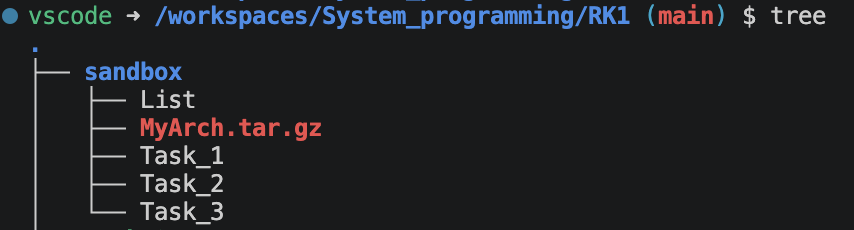

## 2. Вычислительные задачи

1. Разработать программу на языке ассемблера, которая принимает в качестве параметра командной строки значение $2n+1$, выполняет расчет указанного выражения и выводит результат на экран:
$$1+3+5+7+\ldots +(2n+1)$$
Если пользователь ввел четное число, программа должна выдать ошибку.


In [ ]:
format ELF64

public _start

include '../MyLibrary.asm'

section ".data" writeable
    error_msg db "Error: the number is even", 0xA

section ".text" executable
_start:
    pop rax
    cmp rax, 2
    jl exit

    pop rax
    pop rax
    call ATOI ; rcx = 2n+1

    ; делим на 2: rax = n, rdx = остаток
    mov rax, rcx
    xor rdx, rdx
    mov r9, 2
    div r9

    cmp rdx, 0
    je .error

    ; 1+3+5+...+(2n+1) = (n+1)^2
    inc rax
    mul rax
    call print_int
    call exit

    .error:
        mov rax, 1
        mov rdi, 1
        mov rsi, error_msg
        mov rdx, 26
        syscall
        call exit


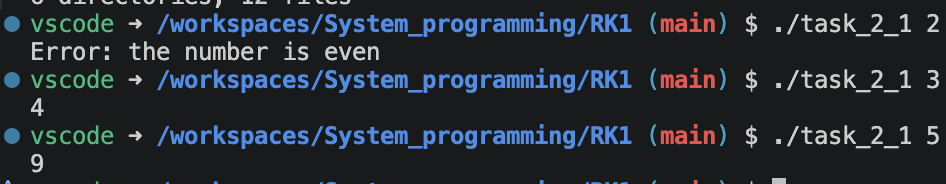

## 3. Работа с файлами


2. Написать программу на языке ассемблера, которая принимает два параметра командной строки: первый -  имя некоторого каталога name, второй - некоторое число $n$. Программа заходит в данный каталог и создает в нем новый каталог с именем name, далее заходит в каталог ./name/name и создает там новый каталог name, делая так $n$ раз.


In [ ]:
format ELF64

public _start

include '../MyLibrary.asm'

section ".text" executable
_start:
    pop rax
    cmp rax, 3
    jl exit

    pop rax
    pop r9 ; имя каталога name
    pop rax
    call ATOI
    mov r8, rcx ; n

    mov rax, 80 ; chdir
    mov rdi, r9
    syscall
    cmp rax, 0
    jl exit

    .loop:
        cmp r8, 0
        jle exit

        mov rax, 83 ; mkdir
        mov rdi, r9
        mov rsi, 755o
        syscall

        mov rax, 80 ; chdir
        mov rdi, r9
        syscall

        dec r8
        jmp .loop


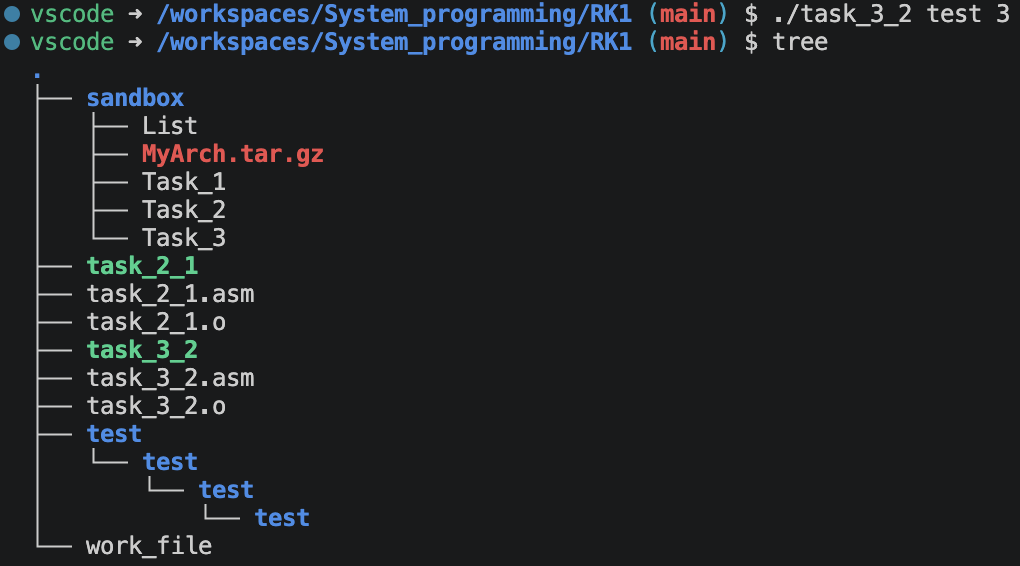

## Генерация заданий по варианту

In [ ]:
import random as rd

Variant = 20
rd.seed(Variant+86554338)

Numbers_of_problems = [rd.sample(range(5),1)[0]+1, rd.sample(range(5),1)[0]+1, rd.sample(range(5),1)[0]+1]
Numbers_of_problems

[3, 1, 2]

# MyLibrary.asm

In [ ]:

section ".data" writeable
    urandom_path db "/dev/urandom", 0

section ".bss" writeable
    buffer rb 255

section ".text" executable

;input rax - intager
print_int:
    push rsi
    push rdi
    push rdx
    call ITOA

    mov rsi, rax
    mov rax, 1
    mov rdi, 1
    syscall

    pop rdx
    pop rdi
    pop rsi

    ret

;The function realizates user input from the keyboard
;input: rsi - place of memory saved input string
input_keyboard:
  push rax
  push rdi
  push rdx

  mov rax, 0
  mov rdi, 0
  mov rdx, 255
  syscall

  xor rcx, rcx
  .loop:
     mov al, [rsi+rcx]
     inc rcx
     cmp rax, 0x0A
     jne .loop
  dec rcx
  mov byte [rsi+rcx], 0

  pop rdx
  pop rdi
  pop rax
  ret


exit:
    mov rax,60
    xor rdi, rdi
    syscall

;input: rax - pointer to the string
;output: rcx - integer
ATOI:
    push rsi ; pointer to end of string
    push rdx ; pointer to the string
    push rbx
    push R9
    push R8 ; хранит в себе не полный результат приобразования

    mov rsi, rax ; rsi должен указывать на конец строки
    mov rbx, rax
    xor R8, R8
    mov R9, 10 ; основание СС

    mov rax, 1 ; здесь хранятся степени 10

    @@: ; двигаем rsi до тех пор пока не встретим символ конца строки
        cmp byte [rsi], 0
        je @f
        inc rsi
        jmp @b
    @@:

    dec rsi
    @@:
    xor rcx, rcx
        mov cl, [rsi] ; Получаем ASCII код цифры
        sub rcx, '0' ; из ASCII получаем само значение цифры
        push rax
        mul rcx ; умножаем степень 10 на цифру

        add R8, rax; складываем результат умножения с предварительным результатом
        pop rax
        mul R9 ; увеличиваем степень 10

        cmp rsi,rbx ; проверяем не закончилось ли число
        je @f
        dec rsi
        jmp @b
    @@:

    mov rcx,R8

    pop R8
    pop R9
    pop rbx
    pop rdx
    pop rsi
    ret

; input rax - intager
; otput:
; rax - buffer
; rdx - len of buffer
ITOA:
    push rsi
    push rdi
    push rbx


    xor rsi, rsi
    cmp rax, 0
    jge @f
    neg rax
    mov byte [buffer], '-'
    inc rsi
    @@:

    push rsi
    mov r10, 10

    @@:
        xor rdx, rdx
        div r10
        add rdx, '0'
        mov [buffer + rsi], dl
        inc rsi

        cmp rax, 0
        jg @b

    mov [buffer + rsi], 10
    mov rdi, rsi
    mov rdx, rsi
    inc rdx
    dec rdi

    pop rsi
    add rsi, buffer
    add rdi, buffer
    call reverse_str

    mov rax, buffer
    pop rbx
    pop rdi
    pop rsi
    ret

; input:
; rsi - start
; rdi - end
reverse_str:
    push rax
    xor rax, rax

    @@:

        cmp rsi, rdi
        jge @f

        mov al, [rsi]
        mov ah, [rdi]
        mov [rsi], ah
        mov [rdi], al

        inc rsi
        dec rdi
        jmp @b
        @@:
    pop rax
    ret

;The function generates a random 64-bit number
;output: rax - random number (0 if could not be read)
random:
    push rdi
    push rsi
    push rdx
    push rcx
    push r11
    push r8
    push 0

    mov rax, 2 ; open
    mov rdi, urandom_path
    xor rsi, rsi
    syscall
    cmp rax, 0
    jl @f
    mov r8, rax

    mov rax, 0
    mov rdi, r8
    mov rsi, rsp
    mov rdx, 8
    syscall

    mov rax, 3
    mov rdi, r8
    syscall
    @@:

    pop rax
    pop r8
    pop r11
    pop rcx
    pop rdx
    pop rsi
    pop rdi
    ret